# Benchmark Multi-Instrumento: Basic Pitch vs Basic Pitch + DSP

Este notebook evalúa cómo afecta el procesamiento de señal digital (**DSP**) a la transcripción automática de audio a MIDI con **Basic Pitch** (Spotify) a través de **múltiples instrumentos** de un mismo track del dataset **BabySlakh**.

## Arquitectura modular empleada:

- **`src/transcriber.py`**: Módulo desacoplado con la clase `BasicPitchTranscriber` y los pipelines independientes:
  - **`AudioPreProcessor`** (Pre-DSP): Filtros acústicos con `Pedalboard` (Highpass, Lowpass, NoiseGate) aplicados a la señal de audio antes de la IA.
  - **`NotePostProcessor`** (Post-DSP): Filtros simbólicos sobre las notas detectadas (rango físico/tesitura del instrumento, duración mínima de notas fantasma).
  - **`TranscriptionPipeline`**: Contenedor modular que une o aísla ambas etapas.
  - **`create_instrument_pipeline()`**: Fábrica automática que parametriza el DSP según los metadatos del instrumento.
- **Evaluación (`mir_eval`)**: Implementada en este notebook para calcular $F_{no}$ (Onset), $F$ (Onset+Offset) y $Acc$ (Frame).

--- 
## 1. Configuración de Rutas, Importaciones y Dependencias

In [1]:
import os
import sys
from pathlib import Path

# ── Configurar sys.path para importar módulos desde src/ y la raíz del proyecto ──
PROJECT_ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
SRC_DIR = PROJECT_ROOT / "src"

for path in [str(SRC_DIR), str(PROJECT_ROOT)]:
    if path not in sys.path:
        sys.path.insert(0, path)

# Asegurar que el directorio de trabajo sea la raíz del proyecto para las rutas relativas
os.chdir(PROJECT_ROOT)

import yaml
import numpy as np
import pretty_midi
import mir_eval
import pandas as pd
import matplotlib.pyplot as plt
import IPython.display as ipd
import warnings

warnings.filterwarnings('ignore')

# ── Importar componentes desde src/transcriber.py ──
from transcriber import (
    BasicPitchTranscriber,
    AudioPreProcessor,
    NotePostProcessor,
    TranscriptionPipeline,
    create_instrument_pipeline,
)

# Función auxiliar para sintetizar PrettyMIDI a audio normalizado
def synthesize_midi(pm: pretty_midi.PrettyMIDI, fs: int = 22050) -> np.ndarray:
    """Sintetiza un objeto PrettyMIDI a un arreglo de audio normalizado (evita clipping)."""
    audio = pm.synthesize(fs=fs)
    max_val = np.max(np.abs(audio))
    if max_val > 0:
        audio = (audio / max_val) * 0.9
    return audio

# Constantes para evaluación
ONSET_TOL = 0.05       # 50 ms de tolerancia temporal en onsets
FRAME_HOP_SEC = 0.01   # Resolución de 10 ms para evaluación a nivel de frame

print(f"✅ Raíz del proyecto: {PROJECT_ROOT}")
print("✅ Módulos de src/ y librerías cargadas correctamente.")

✅ Raíz del proyecto: /home/niik/Documents/proyects/AcusPy
✅ Módulos de src/ y librerías cargadas correctamente.


--- 
## 2. Instanciación del Modelo

La clase `BasicPitchTranscriber` carga y compila los pesos del modelo **una sola vez** en memoria, evitando sobrecostos de re-inicialización al evaluar múltiples pistas e instrumentos.

In [2]:
# Instanciar el transcriptor (mantiene el modelo en memoria)
transcriber = BasicPitchTranscriber()

📦 [BasicPitchTranscriber] Modelo cargado: /home/niik/Documents/proyects/AcusPy/.venv/lib/python3.10/site-packages/basic_pitch/saved_models/icassp_2022/nmp.tflite


--- 
## 3. Demostración de Uso de la Clase

Aquí se observa la flexibilidad del diseño: podemos ejecutar la transcripción **cruda** (`pipeline=None`), usar un **pipeline automático** por instrumento, o construir uno **personalizado** separando explícitamente Pre-DSP y Post-DSP.

In [3]:
# Ejemplo: Stem de bajo de Track00001
demo_audio_path = str(PROJECT_ROOT / "data/babyslakh_16k/Track00001/stems/S03.wav")

# 1. Transcripción Cruda (sin DSP)
res_raw = transcriber.transcribe(demo_audio_path, pipeline=None)
print(f" Crudo: {len(res_raw['note_events'])} notas detectadas")

# 2. Transcripción con Pipeline automático para Bajo
bass_pipeline = create_instrument_pipeline(inst_class="Bass")
res_dsp = transcriber.transcribe(demo_audio_path, pipeline=bass_pipeline)
print(f" Con DSP automático ({bass_pipeline.name}): {len(res_dsp['note_events'])} notas detectadas")
print(f"   - Pre-DSP aplicado: {res_dsp['applied_pre_dsp']}")
print(f"   - Post-DSP aplicado: {res_dsp['applied_post_dsp']}")

# Reproducir el audio resultante del Pre-DSP en la demo
print("\n🎵 Audio resultante procesado por Pre-DSP (Bajo):")
ipd.display(ipd.Audio(res_dsp['audio_processed'], rate=res_dsp['sr']))

Predicting MIDI for /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001/stems/S03.wav...
 Crudo: 576 notas detectadas
Predicting MIDI for /tmp/tmpey6q_aw1.wav...
 Con DSP automático (Pipeline_Bass): 573 notas detectadas
   - Pre-DSP aplicado: True
   - Post-DSP aplicado: True

🎵 Audio resultante procesado por Pre-DSP (Bajo):


### Construcción manual separando Pre-DSP y Post-DSP (Opcional)

También es posible instanciar cada procesador por separado para experimentos finos:

In [4]:
from pedalboard import HighpassFilter, NoiseGate

# Pre-DSP personalizado: corte en 40Hz + compuerta suave
custom_pre = AudioPreProcessor(
    board=[HighpassFilter(cutoff_frequency_hz=40.0), NoiseGate(threshold_db=-35.0)],
    name="Custom_Audio_Pre"
)

# Post-DSP personalizado: solo notas entre E1 (28) y C4 (60), duración mínima 60ms
custom_post = NotePostProcessor(
    pitch_range=(28, 60),
    min_duration_sec=0.06,
    name="Custom_Note_Post"
)

custom_pipeline = TranscriptionPipeline(
    name="Experimento_Bajo_Avanzado",
    audio_preprocessor=custom_pre,
    note_postprocessor=custom_post,
)

print("Pipeline personalizado creado:", custom_pipeline)

Pipeline personalizado creado: TranscriptionPipeline(name='Experimento_Bajo_Avanzado', pre_dsp=True, post_dsp=True)


--- 
## 4. Funciones de Evaluación con `mir_eval`

In [5]:
def midi_to_intervals_and_pitches(pm: pretty_midi.PrettyMIDI) -> tuple[np.ndarray, np.ndarray]:
    """Extrae intervalos [onset, offset] y frecuencias en Hz de un PrettyMIDI."""
    all_notes = []
    for inst in pm.instruments:
        if not inst.is_drum:
            for note in inst.notes:
                all_notes.append((note.start, note.end, note.pitch))
    
    if not all_notes:
        return np.zeros((0, 2)), np.zeros(0)
    
    all_notes.sort(key=lambda x: x[0])
    intervals = np.array([[n[0], n[1]] for n in all_notes])
    pitches_hz = np.array([pretty_midi.note_number_to_hz(n[2]) for n in all_notes])
    return intervals, pitches_hz


def midi_to_frame_frequencies(
    pm: pretty_midi.PrettyMIDI,
    total_duration: float,
    hop_sec: float = FRAME_HOP_SEC,
) -> list[np.ndarray]:
    """Convierte notas MIDI a listas de frecuencias activas en cada frame de tiempo."""
    n_frames = int(np.ceil(total_duration / hop_sec))
    frame_times = np.arange(n_frames) * hop_sec
    
    all_notes = []
    for inst in pm.instruments:
        if not inst.is_drum:
            for note in inst.notes:
                all_notes.append((note.start, note.end, note.pitch))
                
    frame_freqs = []
    for t in frame_times:
        active = [pretty_midi.note_number_to_hz(pitch) for start, end, pitch in all_notes if start <= t < end]
        frame_freqs.append(np.array(active))
    return frame_freqs


def evaluate_prediction(
    gt_midi: pretty_midi.PrettyMIDI,
    pred_midi: pretty_midi.PrettyMIDI,
    total_duration: float,
    onset_tol: float = ONSET_TOL,
    hop_sec: float = FRAME_HOP_SEC,
) -> dict:
    """
    Calcula el conjunto completo de métricas mir_eval:
    - F_no: F-measure en Onset + Pitch (sin requerir offset exacto)
    - F:    F-measure en Onset + Pitch + Offset (tolerancia 20% de duración)
    - Acc:  Accuracy a nivel de frame (multipitch, 10ms)
    """
    ref_int, ref_pitch = midi_to_intervals_and_pitches(gt_midi)
    est_int, est_pitch = midi_to_intervals_and_pitches(pred_midi)
    
    if len(est_int) == 0 or len(ref_int) == 0:
        return {'F_no': 0.0, 'P_no': 0.0, 'R_no': 0.0, 'F': 0.0, 'P': 0.0, 'R': 0.0, 'Acc': 0.0}

    # 1. Onset + Pitch (F_no)
    P_no, R_no, F_no, _ = mir_eval.transcription.precision_recall_f1_overlap(
        ref_int, ref_pitch, est_int, est_pitch,
        onset_tolerance=onset_tol, offset_ratio=None,
    )
    
    # 2. Onset + Pitch + Offset (F)
    P, R, F, _ = mir_eval.transcription.precision_recall_f1_overlap(
        ref_int, ref_pitch, est_int, est_pitch,
        onset_tolerance=onset_tol, offset_ratio=0.2, offset_min_tolerance=0.05,
    )
    
    # 3. Multipitch Frame Accuracy
    n_frames = int(np.ceil(total_duration / hop_sec))
    times = np.arange(n_frames) * hop_sec
    ref_frames = midi_to_frame_frequencies(gt_midi, total_duration, hop_sec)
    est_frames = midi_to_frame_frequencies(pred_midi, total_duration, hop_sec)
    min_l = min(len(ref_frames), len(est_frames), len(times))
    
    mp_results = mir_eval.multipitch.metrics(times[:min_l], ref_frames[:min_l], times[:min_l], est_frames[:min_l])
    acc = mp_results[2]  # Accuracy está en el índice 2
    
    return {
        'P_no': P_no, 'R_no': R_no, 'F_no': F_no,
        'P': P, 'R': R, 'F': F,
        'Acc': acc,
    }

--- 
## 5. Carga de Metadatos y Selección de Instrumentos

Leemos `metadata.yaml` del track para identificar automáticamente los instrumentos disponibles y excluir pistas percusivas (`is_drum: True`).

In [6]:
TRACK_DIR = str(PROJECT_ROOT / "data/babyslakh_16k/Track00001")
METADATA_PATH = os.path.join(TRACK_DIR, "metadata.yaml")

with open(METADATA_PATH, 'r') as f:
    metadata = yaml.safe_load(f)

print(f"=== Track: {TRACK_DIR} ===")
target_stems = []
for stem_id, info in metadata['stems'].items():
    is_drum = info.get('is_drum', False)
    inst_class = info.get('inst_class', 'Unknown')
    prog_name = info.get('midi_program_name', 'Unknown')
    
    wav_path = os.path.join(TRACK_DIR, "stems", f"{stem_id}.wav")
    mid_path = os.path.join(TRACK_DIR, "MIDI", f"{stem_id}.mid")
    
    # Solo evaluamos instrumentos tonales que tengan audio y MIDI existente
    if not is_drum and os.path.exists(wav_path) and os.path.exists(mid_path):
        target_stems.append({
            'stem_id': stem_id,
            'inst_class': inst_class,
            'program_name': prog_name,
            'wav_path': wav_path,
            'mid_path': mid_path,
        })
        print(f"  [✓] {stem_id}: {inst_class} ({prog_name})")
    else:
        print(f"  [-] {stem_id}: {inst_class} (ignorado: drum={is_drum})")

print(f"\nTotal de instrumentos a evaluar: {len(target_stems)}")

=== Track: /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001 ===
  [✓] S00: Guitar (Distortion Guitar)
  [-] S01: Drums (ignorado: drum=True)
  [✓] S02: Piano (Bright Acoustic Piano)
  [✓] S03: Bass (Electric Bass (finger))
  [✓] S04: Strings (continued) (Choir Aahs)
  [✓] S05: Organ (Percussive Organ)
  [-] S06: Sound Effects (ignorado: drum=False)
  [✓] S07: Guitar (Electric Guitar (jazz))
  [✓] S08: Guitar (Distortion Guitar)
  [✓] S09: Organ (Harmonica)
  [✓] S10: Organ (Harmonica)

Total de instrumentos a evaluar: 9


--- 
## 6. Ejecución del Benchmark Multi-Instrumento

Para cada instrumento se evalúan dos condiciones frente a su Ground Truth MIDI:
1. **Crudo (Raw):** Inferencia directa sin DSP (`pipeline=None`).
2. **Con DSP:** Inferencia con Pre-DSP y Post-DSP ajustados a la clase del instrumento vía `create_instrument_pipeline()`.

Guardamos los resultados de cada etapa en `processed_audios` para poder auditar cualquiera de los instrumentos.

In [7]:
benchmark_records = []
processed_audios = {}  # Almacena los datos de los 3 pasos por instrumento

for item in target_stems:
    stem_id = item['stem_id']
    inst_class = item['inst_class']
    prog_name = item['program_name']
    wav_path = item['wav_path']
    mid_path = item['mid_path']
    
    label = f"{inst_class} ({stem_id})"
    print(f"\n{'='*60}\nEvaluando: {label} - {prog_name}\n{'='*60}")
    
    # Cargar Ground Truth MIDI
    gt_midi = pretty_midi.PrettyMIDI(mid_path)
    total_duration = gt_midi.get_end_time()
    
    # 1. Condición: Crudo (Sin DSP)
    print("  -> Ejecutando condición Cruda...")
    res_raw = transcriber.transcribe(wav_path, pipeline=None)
    metrics_raw = evaluate_prediction(gt_midi, res_raw['midi'], total_duration)
    
    # 2. Condición: Con DSP automático según el instrumento
    print(f"  -> Ejecutando condición con DSP ({inst_class})...")
    inst_pipeline = create_instrument_pipeline(inst_class)
    res_dsp = transcriber.transcribe(wav_path, pipeline=inst_pipeline)
    metrics_dsp = evaluate_prediction(gt_midi, res_dsp['midi'], total_duration)
    
    # ── Guardar datos de los 3 pasos ──
    processed_audios[label] = {
        'y_predsp': res_dsp['audio_processed'],  # Paso 1: Audio tras Pre-DSP
        'sr': res_dsp['sr'],
        'inst_class': inst_class,
        'raw_midi': res_dsp['raw_midi'],          # Paso 2: MIDI directo del modelo Basic Pitch
        'midi': res_dsp['midi'],                  # Paso 3: MIDI filtrado con Post-DSP
        'raw_audio_path': wav_path,
    }
    
    # Registrar métricas
    benchmark_records.append({
        'Instrumento': label,
        'Clase': inst_class,
        'Notas GT': sum(len(i.notes) for i in gt_midi.instruments),
        'Notas Crudo': len(res_raw['note_events']),
        'Notas DSP': len(res_dsp['note_events']),
        'F_no (Crudo)': metrics_raw['F_no'],
        'F_no (DSP)': metrics_dsp['F_no'],
        'Δ F_no': metrics_dsp['F_no'] - metrics_raw['F_no'],
        'F (Crudo)': metrics_raw['F'],
        'F (DSP)': metrics_dsp['F'],
        'Δ F': metrics_dsp['F'] - metrics_raw['F'],
        'Acc (Crudo)': metrics_raw['Acc'],
        'Acc (DSP)': metrics_dsp['Acc'],
        'Δ Acc': metrics_dsp['Acc'] - metrics_raw['Acc'],
    })

df_results = pd.DataFrame(benchmark_records)
print("\n✅ Benchmark multi-instrumento finalizado con éxito.")


Evaluando: Guitar (S00) - Distortion Guitar
  -> Ejecutando condición Cruda...
Predicting MIDI for /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001/stems/S00.wav...
  -> Ejecutando condición con DSP (Guitar)...
Predicting MIDI for /tmp/tmp7ypxxdob.wav...

Evaluando: Piano (S02) - Bright Acoustic Piano
  -> Ejecutando condición Cruda...
Predicting MIDI for /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001/stems/S02.wav...
  -> Ejecutando condición con DSP (Piano)...
Predicting MIDI for /tmp/tmpupgj9_6j.wav...

Evaluando: Bass (S03) - Electric Bass (finger)
  -> Ejecutando condición Cruda...
Predicting MIDI for /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001/stems/S03.wav...
  -> Ejecutando condición con DSP (Bass)...
Predicting MIDI for /tmp/tmpwn5mgn_e.wav...

Evaluando: Strings (continued) (S04) - Choir Aahs
  -> Ejecutando condición Cruda...
Predicting MIDI for /home/niik/Documents/proyects/AcusPy/data/babyslakh_16k/Track00001/st

--- 
## 7. Tabla Comparativa de Resultados

A continuación se presenta la tabla resumen. Las columnas $\Delta$ indican la variación producida por el DSP (valores positivos en verde representan mejora).

In [8]:
# Formato visual con gradientes para identificar fácilmente las mejoras
metric_cols = ['F_no (Crudo)', 'F_no (DSP)', 'Δ F_no', 'F (Crudo)', 'F (DSP)', 'Δ F', 'Acc (Crudo)', 'Acc (DSP)', 'Δ Acc']

styled_df = (
    df_results.set_index('Instrumento')[metric_cols]
    .style.format('{:+.4f}', subset=['Δ F_no', 'Δ F', 'Δ Acc'])
    .format('{:.4f}', subset=['F_no (Crudo)', 'F_no (DSP)', 'F (Crudo)', 'F (DSP)', 'Acc (Crudo)', 'Acc (DSP)'])
    .background_gradient(subset=['F_no (DSP)', 'Acc (DSP)'], cmap='Blues')
    .background_gradient(subset=['Δ F_no', 'Δ Acc'], cmap='RdYlGn', vmin=-0.05, vmax=0.05)
    .set_caption("Resultados del Benchmark: Basic Pitch Crudo vs Basic Pitch + DSP por Instrumento")
)

styled_df

,F_no (Crudo),F_no (DSP),Δ F_no,F (Crudo),F (DSP),Δ F,Acc (Crudo),Acc (DSP),Δ Acc
Instrumento,,,,,,,,,
Guitar (S00),0.6114,0.6457,+0.0344,0.4629,0.4574,-0.0055,0.7656,0.7818,+0.0163
Piano (S02),0.8520,0.8558,+0.0039,0.3051,0.3065,+0.0014,0.7400,0.7412,+0.0012
Bass (S03),0.4696,0.4818,+0.0122,0.2049,0.2163,+0.0114,0.1584,0.1611,+0.0026
Strings (continued) (S04),0.1023,0.0984,-0.0040,0.0000,0.0000,+0.0000,0.5242,0.5255,+0.0012
Organ (S05),0.3478,0.3635,+0.0157,0.3030,0.3089,+0.0059,0.3203,0.3458,+0.0255
Guitar (S07),0.6925,0.7011,+0.0086,0.5092,0.5290,+0.0199,0.6358,0.6701,+0.0344
Guitar (S08),0.2679,0.2553,-0.0126,0.0957,0.0957,+0.0001,0.2495,0.2596,+0.0101
Organ (S09),0.3672,0.4323,+0.0651,0.3352,0.3940,+0.0587,0.2605,0.3073,+0.0468
Organ (S10),0.5471,0.5636,+0.0165,0.3988,0.4090,+0.0103,0.3336,0.3441,+0.0105


--- 
## 8. Visualización Comparativa: Impacto del DSP por Instrumento

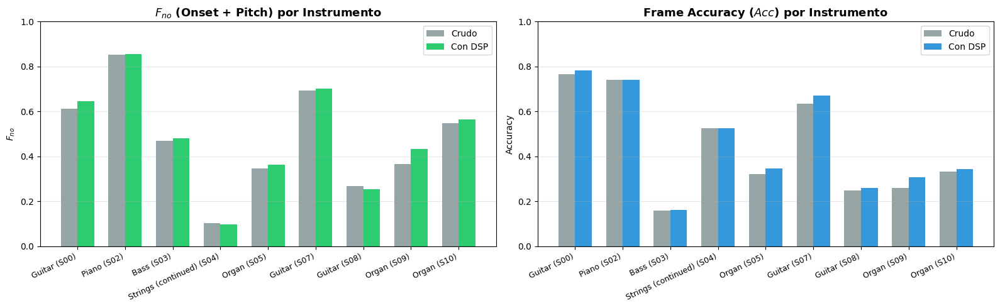

In [9]:
instruments = df_results['Instrumento']
x = np.arange(len(instruments))
width = 0.35

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Gráfico 1: F_no (Onset + Pitch)
ax1.bar(x - width/2, df_results['F_no (Crudo)'], width, label='Crudo', color='#95a5a6')
ax1.bar(x + width/2, df_results['F_no (DSP)'], width, label='Con DSP', color='#2ecc71')
ax1.set_title('$F_{no}$ (Onset + Pitch) por Instrumento', fontsize=13, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(instruments, rotation=25, ha='right', fontsize=9)
ax1.set_ylabel('$F_{no}$')
ax1.set_ylim(0, 1.0)
ax1.legend()
ax1.grid(axis='y', alpha=0.3)

# Gráfico 2: Frame Accuracy
ax2.bar(x - width/2, df_results['Acc (Crudo)'], width, label='Crudo', color='#95a5a6')
ax2.bar(x + width/2, df_results['Acc (DSP)'], width, label='Con DSP', color='#3498db')
ax2.set_title('Frame Accuracy ($Acc$) por Instrumento', fontsize=13, fontweight='bold')
ax2.set_xticks(x)
ax2.set_xticklabels(instruments, rotation=25, ha='right', fontsize=9)
ax2.set_ylabel('Accuracy')
ax2.set_ylim(0, 1.0)
ax2.legend()
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

### Gráfico de Mejora Neta ($\Delta F_{no}$)

Este gráfico destaca directamente la ganancia o pérdida neta al aplicar el pipeline DSP en cada instrumento.

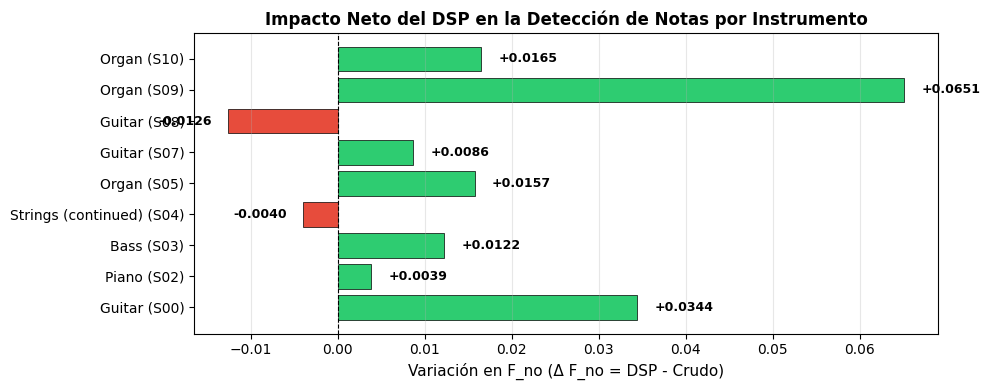

In [10]:
fig, ax = plt.subplots(figsize=(10, 4))

deltas = df_results['Δ F_no']
colors = ['#2ecc71' if d >= 0 else '#e74c3c' for d in deltas]

bars = ax.barh(instruments, deltas, color=colors, edgecolor='black', linewidth=0.5)
ax.axvline(0, color='black', linestyle='--', linewidth=0.8)
ax.set_xlabel('Variación en F_no (Δ F_no = DSP - Crudo)', fontsize=11)
ax.set_title('Impacto Neto del DSP en la Detección de Notas por Instrumento', fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)

# Anotaciones en las barras
for bar in bars:
    w = bar.get_width()
    offset = 0.002 if w >= 0 else -0.008
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f'{w:+.4f}', 
            va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.show()

--- 
## 9. Escucha Comparativa de los 3 Pasos del Pipeline

Aquí se analiza auditivamente la evolución del audio en cada una de las 3 etapas fundamentales:
1. **Paso 1: Pre-DSP (Acústico)** — Señal de audio procesada con filtros de corte y compuerta de ruido de `Pedalboard`.
2. **Paso 2: Modelo Basic Pitch (Simbólico Crudo)** — Notas detectadas por la red neuronal sintetizadas directamente a audio.
3. **Paso 3: Post-DSP (Simbólico Filtrado)** — Notas detectadas tras aplicar las reglas de tesitura y duración mínima.

Selecciona el instrumento a inspeccionar:

In [ ]:
# Puedes cambiar este nombre por cualquiera de los evaluados (ej. 'Bass (S03)', 'Guitar (S00)', 'Piano (S02)', 'Organ (S09)')
selected_instrument = "Guitar (S00)"

# Si el seleccionado no está disponible, tomar el primero de la lista
if selected_instrument not in processed_audios and processed_audios:
    selected_instrument = list(processed_audios.keys())[0]

target_data = processed_audios[selected_instrument]
sr = target_data['sr']

print(f"🎯 Instrumento seleccionado para la escucha de los 3 pasos: {selected_instrument}")

🎯 Instrumento seleccionado para la escucha de los 3 pasos: Bass (S03)


### 🔹 Celda 1/3: Paso 1 — Audio tras Pre-DSP (Acústico)

In [12]:
# ==============================================================================
# CELDA 1/3: PASO 1 - Audio tras Pre-DSP (Filtros acústicos Pedalboard)
# ==============================================================================
y_predsp = target_data['y_predsp']

print(f"🔊 [Paso 1: Pre-DSP] Señal de audio acústica procesada ({selected_instrument}):")
print(f"   Duración: {len(y_predsp)/sr:.2f}s | Sample Rate: {sr} Hz")
ipd.display(ipd.Audio(y_predsp, rate=sr))

🔊 [Paso 1: Pre-DSP] Señal de audio acústica procesada (Bass (S03)):
   Duración: 241.56s | Sample Rate: 22050 Hz


### 🔹 Celda 2/3: Paso 2 — Salida del Modelo Basic Pitch (Sintetizado sin Post-DSP)

In [13]:
# ==============================================================================
# CELDA 2/3: PASO 2 - Salida del Modelo Basic Pitch (Sintetizado sin Post-DSP)
# ==============================================================================
# Sintetizamos las notas brutas extraídas por la red neuronal antes de los filtros de tesitura/duración
y_model = synthesize_midi(target_data['raw_midi'], fs=sr)
total_raw_notes = sum(len(i.notes) for i in target_data['raw_midi'].instruments)

print(f"🤖 [Paso 2: Modelo Basic Pitch] Notas detectadas por la IA crudas ({selected_instrument}):")
print(f"   Total de notas detectadas: {total_raw_notes} notas")
ipd.display(ipd.Audio(y_model, rate=sr))

🤖 [Paso 2: Modelo Basic Pitch] Notas detectadas por la IA crudas (Bass (S03)):
   Total de notas detectadas: 573 notas


### 🔹 Celda 3/3: Paso 3 — Salida con Post-DSP aplicado (Sintetizado filtrado)

In [14]:
# ==============================================================================
# CELDA 3/3: PASO 3 - Salida con Post-DSP aplicado (Sintetizado filtrado)
# ==============================================================================
# Sintetizamos las notas finales tras aplicar el purgado de notas fantasma y tesitura del instrumento
y_postdsp = synthesize_midi(target_data['midi'], fs=sr)
total_clean_notes = sum(len(i.notes) for i in target_data['midi'].instruments)

print(f"🔧 [Paso 3: Post-DSP] Notas finales tras filtrado simbólico ({selected_instrument}):")
print(f"   Total de notas limpias: {total_clean_notes} notas (filtradas {total_raw_notes - total_clean_notes})")
ipd.display(ipd.Audio(y_postdsp, rate=sr))

🔧 [Paso 3: Post-DSP] Notas finales tras filtrado simbólico (Bass (S03)):
   Total de notas limpias: 573 notas (filtradas 0)
